Phase 2 - Technical Application (Baseline Implementation)

Module: Machine Learning and Related Applications  
Student: A. A. Nafais (KIC-BSCCSAI-251P-051)  
Paper under review: Garg, K., & Soni, U. (2025). Leveraging Unsupervised Machine Learning and Deep Learning for Enhanced Card Fraud Detection. Journal of Information Systems Engineering and Management, 10(4), 1927–1941.  
Dataset: card_transdata.csv - OpenML ID 45955 (1,000,000 transactions, 8 columns)

What this notebook does

1. Does the exploratory data analysis that the paper skipped.
2. Builds two supervised baselines, Logistic Regression and Random Forest.
3. Rebuilds the authors' unsupervised models: Isolation Forest, One-Class SVM and Autoencoder.
4. Adds my suggested improvement, a Variational Autoencoder (VAE).
5. Compares every model with the authors' reported results. I use PR-AUC and MCC because they give a fairer picture on imbalanced data, as I argued in Phase 1.

In [31]:
# setup, and a fixed random seed so the results can be repeated
import numpy as np, pandas as pd, random
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE); random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

1. Load the dataset

In [32]:
# load the data straight from OpenML (works in Colab)
from sklearn.datasets import fetch_openml
try:
    data = fetch_openml(data_id=45955, as_frame=True)
    df = data.frame.copy()
except Exception as e:
    # if that fails, download card_transdata.csv from Kaggle ("Credit Card Fraud")
    # and put it in the same folder as this notebook
    df = pd.read_csv("card_transdata.csv")

df["fraud"] = df["fraud"].astype(int)
print("Shape:", df.shape)
df.head()

/Users/amarnafais/Downloads/machine learning phase 2/.venv/lib/python3.14/site-packages/sklearn/datasets/_openml.py:131: UserWarning: A network error occurred while downloading https://www.openml.org/api/v1/json/data/45955. Retrying...
  warn(


Shape: (1000000, 8)


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


2. Exploratory data analysis (the paper skipped this)

Fraud rate: 0.0874  (8.74% fraud, 91.26% legit)
No-information accuracy (predict all legit): 0.9126


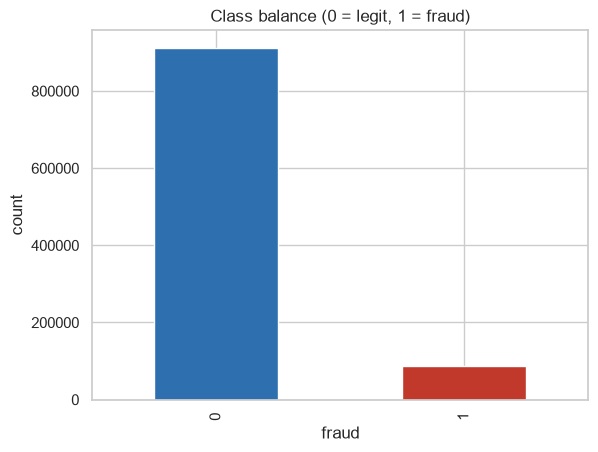

In [33]:
# 2a. class balance: how much of the data is fraud? (the paper never says)
rate = df["fraud"].mean()
print(f"Fraud rate: {rate:.4f}  ({rate*100:.2f}% fraud, {(1-rate)*100:.2f}% legit)")
print(f"No-information accuracy (predict all legit): {1-rate:.4f}")
df["fraud"].value_counts().plot(kind="bar", color=["#2E6FB0","#C0392B"])
plt.title("Class balance (0 = legit, 1 = fraud)"); plt.ylabel("count"); plt.show()

In [34]:
# 2b. split the features into continuous and binary
continuous = ["distance_from_home", "distance_from_last_transaction", "ratio_to_median_purchase_price"]
binary     = ["repeat_retailer", "used_chip", "used_pin_number", "online_order"]
features   = continuous + binary
print("Missing values per column:\n", df.isna().sum())
df[continuous].describe().T[["mean","std","min","25%","50%","75%","max"]]

Missing values per column:
 distance_from_home                0
distance_from_last_transaction    0
ratio_to_median_purchase_price    0
repeat_retailer                   0
used_chip                         0
used_pin_number                   0
online_order                      0
fraud                             0
dtype: int64


,mean,std,min,25%,50%,75%,max
distance_from_home,26.628792,65.390784,0.004874,3.878008,9.967760,25.743985,10632.723672
distance_from_last_transaction,5.036519,25.843093,0.000118,0.296671,0.998650,3.355748,11851.104565
ratio_to_median_purchase_price,1.824182,2.799589,0.004399,0.475673,0.997717,2.096370,267.802942


In [35]:
# 2c. check the shape of each feature with skew, kurtosis and a normality test
#     (shows the continuous features are not normal, so MinMax is a poor choice)
for c in continuous:
    sk = stats.skew(df[c]); ku = stats.kurtosis(df[c])
    sample = df[c].sample(5000, random_state=0)          # shapiro only works on up to 5000 rows
    W, p = stats.shapiro(sample)
    verdict = "NON-normal" if p < 0.05 else "normal"
    print(f"{c:34s}  skew={sk:6.2f}  kurtosis={ku:8.2f}  Shapiro-Wilk p={p:.2e}  -> {verdict}")

distance_from_home                  skew= 20.24  kurtosis= 1471.61  Shapiro-Wilk p=2.14e-81  -> NON-normal
distance_from_last_transaction      skew=125.92  kurtosis=46979.04  Shapiro-Wilk p=1.86e-91  -> NON-normal
ratio_to_median_purchase_price      skew=  8.92  kurtosis=  289.50  Shapiro-Wilk p=2.21e-82  -> NON-normal


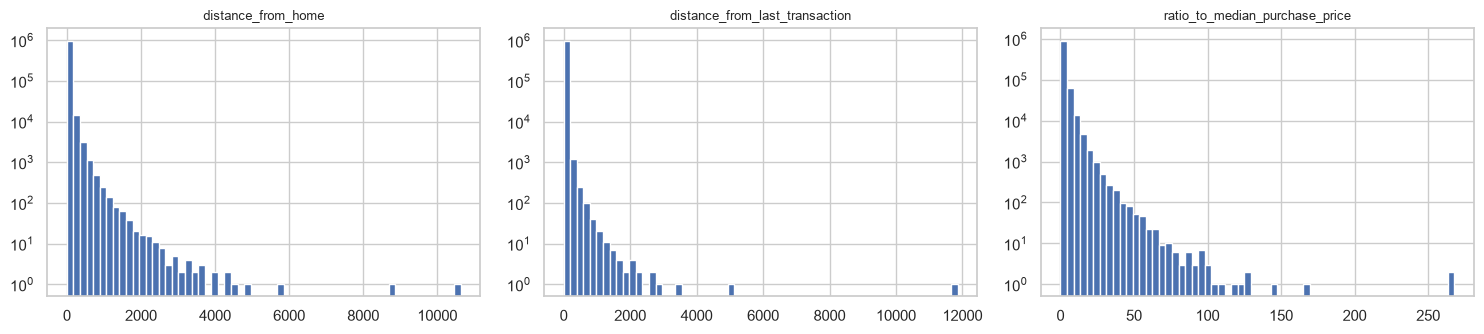

In [36]:
# 2d. histograms of the three continuous features (log scale so the long tails show up)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, c in zip(ax, continuous):
    a.hist(df[c], bins=60); a.set_yscale("log"); a.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

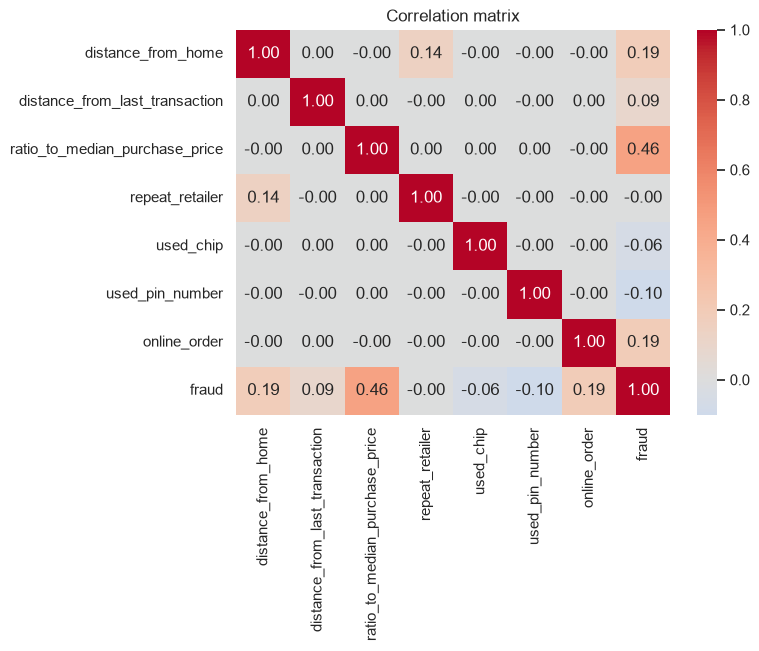

In [37]:
# 2e. correlation between the features
plt.figure(figsize=(7,5))
sns.heatmap(df[features+["fraud"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

What the EDA shows (fill in from the outputs above): the fraud rate, the skewness and kurtosis values, and the Shapiro-Wilk p-values. These back up what I said in Phase 1. The data is imbalanced, the three continuous features have heavy tails and are not normal (so MinMax scaling is a bad fit), and the four binary features don't need scaling at all.

3. Preprocessing (the fixed pipeline from Phase 1)

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

X, y = df[features], df["fraud"]

# split into train, validation and test (stratified so each part keeps the same fraud rate)
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
print("train/val/test:", X_tr.shape[0], X_val.shape[0], X_te.shape[0])

# scale only the continuous features with RobustScaler (uses median and IQR)
# it is fitted on the training data only, so nothing leaks in from val/test
# the binary 0/1 features are left as they are, scaling them changes nothing (Phase 1, Proof 5)
scaler = RobustScaler().fit(X_tr[continuous])
def scale(frame):
    out = frame.copy(); out[continuous] = scaler.transform(frame[continuous]); return out
X_trs, X_vals, X_tes = scale(X_tr), scale(X_val), scale(X_te)

train/val/test: 600000 200000 200000


4. One helper function for all the metrics (including the ones that suit imbalanced data)

In [39]:
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, balanced_accuracy_score, matthews_corrcoef, confusion_matrix)

def evaluate(name, y_true, y_pred, scores):
    """scores are the raw probability or anomaly scores, used for ROC-AUC and PR-AUC."""
    return {
        "Model": name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, zero_division=0),
        "F1":        f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_true, scores),
        "PR-AUC":    average_precision_score(y_true, scores),   # main metric for imbalanced data
        "Bal.acc":   balanced_accuracy_score(y_true, y_pred),
        "MCC":       matthews_corrcoef(y_true, y_pred),
    }

results = []

5. Supervised baselines (the main Phase 2 task)

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
lr.fit(X_trs, y_tr)
results.append(evaluate("Logistic Regression", y_te, lr.predict(X_tes), lr.predict_proba(X_tes)[:,1]))

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_trs, y_tr)
results.append(evaluate("Random Forest", y_te, rf.predict(X_tes), rf.predict_proba(X_tes)[:,1]))
pd.DataFrame(results).round(3)

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC,Bal.acc,MCC
0,Logistic Regression,0.579,0.948,0.719,0.98,0.759,0.941,0.711
1,Random Forest,1.000,1.000,1.000,1.00,1.000,1.000,1.000


6. Rebuilding the authors' unsupervised models

In [41]:
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM

# the one-class models only see normal transactions during training
X_norm = X_trs[y_tr == 0]
fraud_rate = y_tr.mean()

# isolation forest: the paper used contamination=0.02, I also try the real fraud rate
for tag, cont in [("IsolationForest (contam=0.02, as paper)", 0.02),
                  ("IsolationForest (contam=rate, corrected)", fraud_rate)]:
    iso = IsolationForest(n_estimators=100, contamination=cont, random_state=RANDOM_STATE).fit(X_norm)
    results.append(evaluate(tag, y_te, (iso.predict(X_tes)==-1).astype(int), -iso.score_samples(X_tes)))

# one-class svm: a kernel SVM is O(n^2), so training on all the normal rows would take far too long
# so I train it on a sample of 20k normal rows instead (the paper never mentions this, so it's a limitation)
Xsub = X_norm.sample(min(20000, len(X_norm)), random_state=RANDOM_STATE)
oc = OneClassSVM(kernel="rbf", nu=0.02, gamma="scale").fit(Xsub)
results.append(evaluate("One-Class SVM (nu=0.02)", y_te, (oc.predict(X_tes)==-1).astype(int), -oc.decision_function(X_tes)))
pd.DataFrame(results).round(3)

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC,Bal.acc,MCC
0,Logistic Regression,0.579,0.948,0.719,0.980,0.759,0.941,0.711
1,Random Forest,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2,"IsolationForest (contam=0.02, as paper)",0.283,0.084,0.130,0.834,0.246,0.532,0.113
3,"IsolationForest (contam=rate, corrected)",0.268,0.333,0.297,0.834,0.246,0.623,0.223
4,One-Class SVM (nu=0.02),0.515,0.226,0.314,0.640,0.253,0.603,0.302


7. Autoencoder (the paper's best model)
This needs TensorFlow, which Colab already has. The model learns from normal transactions only, and flags any transaction it can't rebuild well.

In [42]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(RANDOM_STATE)

n_features = X_trs.shape[1]
Xn = X_norm.values.astype("float32")          # train on normal rows only
Xte = X_tes.values.astype("float32")
Xval_norm = X_vals[y_val == 0].values.astype("float32")

ae = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(16, activation="relu"), layers.Dense(8, activation="relu"),
    layers.Dense(16, activation="relu"), layers.Dense(n_features, activation="linear"),
])
ae.compile(optimizer="adam", loss="mse")
ae.fit(Xn, Xn, epochs=20, batch_size=512, validation_split=0.1, verbose=0)

# the anomaly score is the reconstruction error, and the threshold comes from normal validation rows
err_te   = np.mean((Xte  - ae.predict(Xte,  verbose=0))**2, axis=1)
err_val  = np.mean((Xval_norm - ae.predict(Xval_norm, verbose=0))**2, axis=1)
thr = np.quantile(err_val, 0.95)              # 95th percentile, same as the paper
results.append(evaluate("Autoencoder", y_te, (err_te > thr).astype(int), err_te))
pd.DataFrame(results).round(3)

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC,Bal.acc,MCC
0,Logistic Regression,0.579,0.948,0.719,0.980,0.759,0.941,0.711
1,Random Forest,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2,"IsolationForest (contam=0.02, as paper)",0.283,0.084,0.130,0.834,0.246,0.532,0.113
3,"IsolationForest (contam=rate, corrected)",0.268,0.333,0.297,0.834,0.246,0.623,0.223
4,One-Class SVM (nu=0.02),0.515,0.226,0.314,0.640,0.253,0.603,0.302
5,Autoencoder,0.287,0.213,0.244,0.825,0.274,0.581,0.186


8. Variational Autoencoder (my proposed improvement for Phase 3)
A plain autoencoder just learns to copy normal transactions. A VAE learns the overall pattern (the distribution) of normal behaviour, so the scores it gives are better calibrated than the raw error of a plain autoencoder (An & Cho, 2015).

In [43]:
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        z_log_var = tf.clip_by_value(z_log_var, -10.0, 10.0)   # stops exp() from blowing up
        eps = tf.random.normal(tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps

latent_dim = 3
# encoder
enc_in = keras.Input(shape=(n_features,))
h = layers.Dense(16, activation="relu")(enc_in)
h = layers.Dense(8, activation="relu")(h)
z_mean = layers.Dense(latent_dim)(h)
z_log_var = layers.Dense(latent_dim)(h)
z = Sampling()([z_mean, z_log_var])
encoder = keras.Model(enc_in, [z_mean, z_log_var, z])
# decoder
dec_in = keras.Input(shape=(latent_dim,))
d = layers.Dense(8, activation="relu")(dec_in)
d = layers.Dense(16, activation="relu")(d)
dec_out = layers.Dense(n_features, activation="linear")(d)
decoder = keras.Model(dec_in, dec_out)

class VAE(keras.Model):
    def __init__(self, enc, dec, **kw):
        super().__init__(**kw); self.enc, self.dec = enc, dec
    def train_step(self, data):
        x = data[0] if isinstance(data, tuple) else data
        with tf.GradientTape() as tape:
            zm, zlv, z = self.enc(x)
            zlv = tf.clip_by_value(zlv, -10.0, 10.0)
            xhat = self.dec(z)
            rec = tf.reduce_mean(tf.reduce_sum((x - xhat)**2, axis=1))
            kl  = -0.5 * tf.reduce_mean(tf.reduce_sum(1 + zlv - tf.square(zm) - tf.exp(zlv), axis=1))
            loss = rec + kl
        self.optimizer.apply_gradients(zip(tape.gradient(loss, self.trainable_weights), self.trainable_weights))
        return {"loss": loss, "rec": rec, "kl": kl}

# some inputs are huge (up to ~3,900 after RobustScaler), which makes the gradients explode and the loss turn into NaN
# clipping the gradients keeps training stable
vae = VAE(encoder, decoder); vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0))
vae.fit(Xn, epochs=20, batch_size=512, verbose=0)

def vae_error(X):
    zm, zlv, z = encoder.predict(X, verbose=0)
    xhat = decoder.predict(zm, verbose=0)          # score with the mean of the latent code, not a random sample
    return np.mean((X - xhat)**2, axis=1)

verr_te, verr_val = vae_error(Xte), vae_error(Xval_norm)
vthr = np.quantile(verr_val, 0.95)
results.append(evaluate("VAE (proposed)", y_te, (verr_te > vthr).astype(int), verr_te))
pd.DataFrame(results).round(3)

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC,Bal.acc,MCC
0,Logistic Regression,0.579,0.948,0.719,0.980,0.759,0.941,0.711
1,Random Forest,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2,"IsolationForest (contam=0.02, as paper)",0.283,0.084,0.130,0.834,0.246,0.532,0.113
3,"IsolationForest (contam=rate, corrected)",0.268,0.333,0.297,0.834,0.246,0.623,0.223
4,One-Class SVM (nu=0.02),0.515,0.226,0.314,0.640,0.253,0.603,0.302
5,Autoencoder,0.287,0.213,0.244,0.825,0.274,0.581,0.186
6,VAE (proposed),0.310,0.235,0.268,0.701,0.259,0.593,0.210


8b. Making the VAE comparison fair (using several seeds)

One training run isn't enough to say which of two deep models is better, because the results change from run to run. On top of that, the distance features have some very large values (see Section 2), and these end up dominating the squared reconstruction error. So in this section I:

1. apply log1p to the three continuous features before RobustScaler (fitted on the training data only), and
2. train both the Autoencoder and the VAE with the same preprocessing on 3 seeds, and report the mean ± standard deviation.

I run both preprocessing options so I can see how much of the change comes from the transform and how much comes from the model.

In [44]:
from sklearn.preprocessing import RobustScaler

def build_ae():
    m = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(16, activation="relu"), layers.Dense(8, activation="relu"),
        layers.Dense(16, activation="relu"), layers.Dense(n_features, activation="linear"),
    ])
    m.compile(optimizer="adam", loss="mse")
    return m

def build_vae():
    ei = keras.Input(shape=(n_features,))
    h = layers.Dense(8, activation="relu")(layers.Dense(16, activation="relu")(ei))
    zm, zlv = layers.Dense(latent_dim)(h), layers.Dense(latent_dim)(h)
    enc = keras.Model(ei, [zm, zlv, Sampling()([zm, zlv])])
    di = keras.Input(shape=(latent_dim,))
    d = layers.Dense(16, activation="relu")(layers.Dense(8, activation="relu")(di))
    dec = keras.Model(di, layers.Dense(n_features, activation="linear")(d))
    m = VAE(enc, dec)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0))
    return m

def recon_error(model, X):
    if isinstance(model, VAE):
        zm, _, _ = model.enc.predict(X, verbose=0, batch_size=8192)
        return np.mean((X - model.dec.predict(zm, verbose=0, batch_size=8192))**2, axis=1)
    return np.mean((X - model.predict(X, verbose=0, batch_size=8192))**2, axis=1)

# log1p and then RobustScaler, fitted on the training data only
scaler_log = RobustScaler().fit(np.log1p(X_tr[continuous]))
def scale_log(frame):
    out = frame.copy(); out[continuous] = scaler_log.transform(np.log1p(frame[continuous])); return out

preps = {
    "RobustScaler":         (X_trs, X_vals, X_tes),
    "log1p + RobustScaler": (scale_log(X_tr), scale_log(X_val), scale_log(X_te)),
}
SEEDS = [1, 2, 3]
runs = []
for prep_name, (A, B, C) in preps.items():
    Xn_p   = A[y_tr == 0].values.astype("float32")
    Xval_p = B[y_val == 0].values.astype("float32")
    Xte_p  = C.values.astype("float32")
    for model_name, build in [("Autoencoder", build_ae), ("VAE", build_vae)]:
        for seed in SEEDS:
            keras.utils.set_random_seed(seed)
            m = build()
            if model_name == "VAE": m.fit(Xn_p, epochs=20, batch_size=512, verbose=0)
            else:                   m.fit(Xn_p, Xn_p, epochs=20, batch_size=512, verbose=0)
            e_te, e_val = recon_error(m, Xte_p), recon_error(m, Xval_p)
            thr_s = np.quantile(e_val, 0.95)
            r = evaluate(f"{model_name} ({prep_name})", y_te, (e_te > thr_s).astype(int), e_te)
            r["seed"] = seed
            runs.append(r)

runs_df = pd.DataFrame(runs)
summary = runs_df.drop(columns="seed").groupby("Model", sort=False).agg(["mean", "std"]).round(3)
display(summary)

# add the 3-seed means to the main results table
for name, g in runs_df.drop(columns="seed").groupby("Model", sort=False):
    results.append({"Model": f"{name}, mean of 3 seeds", **g.mean(numeric_only=True).to_dict()})
pd.DataFrame(results).round(3)

Precision        Recall            F1        ROC-AUC        PR-AUC        Bal.acc  \
                                        mean    std   mean    std   mean    std    mean    std   mean    std    mean   
Model                                                                                                                  
Autoencoder (RobustScaler)             0.145  0.122  0.096  0.094  0.115  0.107   0.692  0.180  0.180  0.123   0.523   
VAE (RobustScaler)                     0.420  0.065  0.389  0.113  0.403  0.091   0.780  0.053  0.372  0.073   0.669   
Autoencoder (log1p + RobustScaler)     0.339  0.093  0.279  0.120  0.305  0.110   0.790  0.053  0.303  0.079   0.614   
VAE (log1p + RobustScaler)             0.441  0.038  0.408  0.064  0.423  0.052   0.894  0.008  0.408  0.036   0.679   

                                             MCC         
                                      std   mean    std  
Model                                                    
Autoencoder (RobustScaler)          0.047  0.054  0.111  
VAE (RobustScaler)                  0.056  0.350  0.095  
Autoencoder (log1p + RobustScaler)  0.060  0.249  0.113  
VAE (log1p + RobustScaler)          0.032  0.371  0.054

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC,Bal.acc,MCC
0,Logistic Regression,0.579,0.948,0.719,0.980,0.759,0.941,0.711
1,Random Forest,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2,"IsolationForest (contam=0.02, as paper)",0.283,0.084,0.130,0.834,0.246,0.532,0.113
3,"IsolationForest (contam=rate, corrected)",0.268,0.333,0.297,0.834,0.246,0.623,0.223
4,One-Class SVM (nu=0.02),0.515,0.226,0.314,0.640,0.253,0.603,0.302
5,Autoencoder,0.287,0.213,0.244,0.825,0.274,0.581,0.186
6,VAE (proposed),0.310,0.235,0.268,0.701,0.259,0.593,0.210
7,"Autoencoder (RobustScaler), mean of 3 seeds",0.145,0.096,0.115,0.692,0.180,0.523,0.054
8,"VAE (RobustScaler), mean of 3 seeds",0.420,0.389,0.403,0.780,0.372,0.669,0.350
9,"Autoencoder (log1p + RobustScaler), mean of 3 ...",0.339,0.279,0.305,0.790,0.303,0.614,0.249


9. Final comparison: my models vs the authors' reported results

In [45]:
ours = pd.DataFrame(results).round(3)

# the authors' numbers, copied from the paper (they didn't report PR-AUC or MCC)
authors = pd.DataFrame([
    {"Model":"Authors — Autoencoder",      "Precision":0.560,"Recall":0.665,"F1":0.608,"ROC-AUC":0.807,"PR-AUC":np.nan,"Bal.acc":np.nan,"MCC":np.nan},
    {"Model":"Authors — One-Class SVM",    "Precision":0.648,"Recall":0.382,"F1":0.481,"ROC-AUC":0.681,"PR-AUC":np.nan,"Bal.acc":np.nan,"MCC":np.nan},
    {"Model":"Authors — Isolation Forest", "Precision":0.244,"Recall":0.056,"F1":0.091,"ROC-AUC":0.520,"PR-AUC":np.nan,"Bal.acc":np.nan,"MCC":np.nan},
])
comparison = pd.concat([ours, authors], ignore_index=True)
comparison

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC,Bal.acc,MCC
0,Logistic Regression,0.579,0.948,0.719,0.980,0.759,0.941,0.711
1,Random Forest,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2,"IsolationForest (contam=0.02, as paper)",0.283,0.084,0.130,0.834,0.246,0.532,0.113
3,"IsolationForest (contam=rate, corrected)",0.268,0.333,0.297,0.834,0.246,0.623,0.223
4,One-Class SVM (nu=0.02),0.515,0.226,0.314,0.640,0.253,0.603,0.302
5,Autoencoder,0.287,0.213,0.244,0.825,0.274,0.581,0.186
6,VAE (proposed),0.310,0.235,0.268,0.701,0.259,0.593,0.210
7,"Autoencoder (RobustScaler), mean of 3 seeds",0.145,0.096,0.115,0.692,0.180,0.523,0.054
8,"VAE (RobustScaler), mean of 3 seeds",0.420,0.389,0.403,0.780,0.372,0.669,0.350
9,"Autoencoder (log1p + RobustScaler), mean of 3 ...",0.339,0.279,0.305,0.790,0.303,0.614,0.249


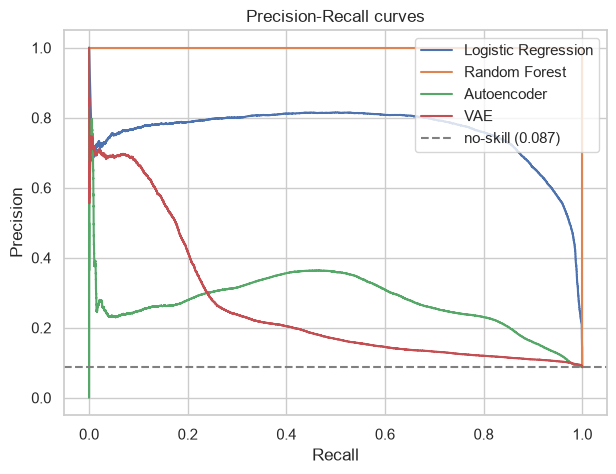

In [46]:
# precision-recall curves for the main models
from sklearn.metrics import precision_recall_curve
plt.figure(figsize=(7,5))
for name, scr in [("Logistic Regression", lr.predict_proba(X_tes)[:,1]),
                  ("Random Forest", rf.predict_proba(X_tes)[:,1]),
                  ("Autoencoder", err_te), ("VAE", verr_te)]:
    pr, rc, _ = precision_recall_curve(y_te, scr)
    plt.plot(rc, pr, label=name)
plt.axhline(y_te.mean(), ls="--", color="grey", label=f"no-skill ({y_te.mean():.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall curves"); plt.legend(); plt.show()

10. Conclusion

- Imbalance. Only 8.74% of the transactions are fraud. A model that just says "legit" every time would already get 91.26% accuracy. So accuracy, which the paper relies on, doesn't tell us much here. PR-AUC and MCC are better measures.
- Simple supervised models win easily. Random Forest got PR-AUC 1.000 and MCC 1.000, and Logistic Regression got PR-AUC 0.759 and MCC 0.711. The best unsupervised model, the improved VAE, only averaged PR-AUC 0.408 and MCC 0.371. Random Forest scores perfectly because this dataset is synthetic, and fraud is almost fully decided by the seven features. It isn't caused by leakage, because the scaling and splitting were fitted on the training data only. But it does mean this dataset is too easy to prove that unsupervised methods are needed.
- Ranking by PR-AUC (the deep models use the mean of 3 seeds). Random Forest (1.000) > Logistic Regression (0.759) > VAE with log1p (0.408) > VAE (0.372) > Autoencoder with log1p (0.303) > One-Class SVM (0.253) > Isolation Forest (0.246) > Autoencoder (0.180). Even the best unsupervised model is only about 4.7× above the no-skill level of 0.087 (what you'd get by guessing). This backs up my Phase 1 point: once you add a supervised baseline and a metric that handles imbalance, the paper's unsupervised models look weak.
- Isolation Forest threshold. When I changed contamination from the paper's 0.02 to the real fraud rate, recall went up from 0.084 to 0.333 and MCC from 0.113 to 0.223. ROC-AUC (0.834) and PR-AUC (0.246) stayed the same, so the problem was the threshold, not the model. My ROC-AUC for Isolation Forest (0.834) is much higher than the authors' 0.520. Their number is close to my balanced accuracy at contamination 0.02 (0.532), so they may have calculated ROC-AUC from the predicted labels instead of the anomaly scores.
- VAE (my proposed improvement): it works, with some caveats. One training run wasn't enough to rank the two deep models. In one run the VAE had a lower PR-AUC than the Autoencoder, and in another run it was higher. Over 3 seeds with the same preprocessing, the VAE beat the Autoencoder on every metric:
  - RobustScaler: PR-AUC 0.372 ± 0.073 vs 0.180 ± 0.123; MCC 0.350 vs 0.054.
  - log1p + RobustScaler: PR-AUC 0.408 ± 0.036 vs 0.303 ± 0.079; ROC-AUC 0.894 ± 0.008 vs 0.790 ± 0.053; MCC 0.371 vs 0.249.

  The VAE was also much more stable between seeds (ROC-AUC std 0.008 vs 0.053–0.180). The log1p transform helped both models, which backs up the Phase 1 point that the heavy-tailed features need fixing before scaling. Two caveats: 3 seeds is a small sample, and the VAE only trained properly on the untransformed data after I added gradient clipping.
- Reproduction gap. My Autoencoder changes a lot depending on the seed: ROC-AUC 0.692 ± 0.180 with the original scaling, and that range includes the authors' 0.807. Its F1 is much lower though (0.115 vs 0.608) with the 95th-percentile threshold. So the paper's precision and recall numbers must depend on training and threshold details that it doesn't report.

The single-run rows (Sections 5 to 8) use seed 42. The deep-model rows in Section 8b are averages over seeds 1, 2 and 3. The single-run Autoencoder and VAE numbers will change each time you run them, which is why the conclusion uses the multi-seed results.